In [2]:
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical

The neural network architecture that is gonna be implementaed is the one that is shown below \
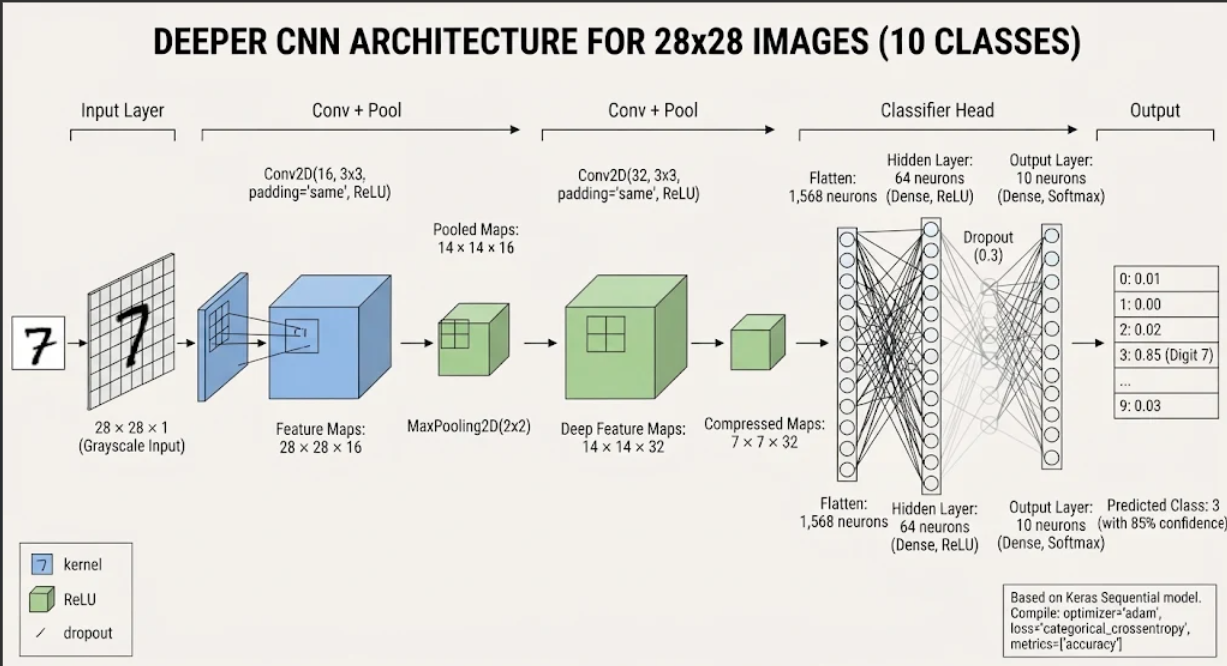

In [3]:
#define the number of classes and load the dataset
num_classes=10
(train_images,train_labels),(test_images,test_labels)=keras.datasets.mnist.load_data()
train_images=train_images.astype("float32")/255.0
test_images=test_images.astype("float32")/255.0
train_images=np.expand_dims(train_images,axis=-1)
test_images=np.expand_dims(test_images,axis=-1)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
#one-hode encodig in labels for the categorical_crossentropy
train_labels_cat=to_categorical(train_labels,num_classes)
test_labels_cat=to_categorical(test_labels,num_classes)

In [13]:
#build the CNN architecture shown in the image
def build_cnn():
  model=keras.Sequential([
      keras.Input(shape=(28,28,1)),
      layers.Conv2D(16,kernel_size=3,padding="same",activation="relu"),
      layers.MaxPooling2D(pool_size=2),
      layers.Conv2D(32,kernel_size=3,padding="same",activation="relu"),
      layers.MaxPooling2D(pool_size=2),
      layers.Flatten(),
      layers.Dense(64,activation="relu"),
      layers.Dropout(0.3),
      layers.Dense(num_classes,activation="softmax")
  ])

  model.compile(
      optimizer="adam",
      loss='categorical_crossentropy',
      metrics=['accuracy']
  )
  return model

In [15]:
#call build cnn function and print the summary of my params
model=build_cnn()
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,866 (413.54 KB)

 Trainable params: 105,866 (413.54 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
#train model
history=model.fit(
    train_images,
    train_labels_cat,
    batch_size=128,
    epochs=3,
    validation_data=(test_images,test_labels_cat)
)

Epoch 1/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 37s 79ms/step - accuracy: 0.9830 - loss: 0.0574 - val_accuracy: 0.9872 - val_loss: 0.0348
Epoch 2/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 37s 78ms/step - accuracy: 0.9845 - loss: 0.0506 - val_accuracy: 0.9885 - val_loss: 0.0330
Epoch 3/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 38s 81ms/step - accuracy: 0.9857 - loss: 0.0450 - val_accuracy: 0.9895 - val_loss: 0.0313


In [18]:
#run tests
test_lostt,test_acc=model.evaluate(test_images,test_labels_cat,verbose=0)
print(f"original model test accuracy {test_acc:.4f}")

original model test accuracy 0.9895


In [21]:
#save model
weights_path="cnn_mnist.weights.h5"
model.save_weights(weights_path)
print(f"saved weights at {weights_path}")

saved weights at cnn_mnist.weights.h5


In [22]:
#reload model
reloaded_model=build_cnn()
reloaded_model.load_weights(weights_path)

reloaded_loss,reloaded_Acc=reloaded_model.evaluate(test_images,test_labels_cat,verbose=0)
print(f"reloaded model test accuracy {reloaded_Acc:.4f}")

reloaded model test accuracy 0.9895
